<a href="https://colab.research.google.com/github/Rahma000882/AI-Project/blob/main/Titanic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Titanic**

| Feature Name    | Description                                                                                     |
| --------------- | ----------------------------------------------------------------------------------------------- |
| **PassengerId** | Unique number assigned to each passenger.                                                       |
| **Survived**    | Indicates whether the passenger survived the Titanic disaster. The label we predict.            |
| **Pclass**      | Represents the passenger’s travel class on the ship, which reflects social and economic status. |
| **Name**        | The full recorded name of the passenger, including title (Mr, Mrs, Miss, etc.).                 |
| **Sex**         | Shows whether the passenger was male or female.                                                 |
| **Age**         | Represents how old the passenger was.                                                           |
| **SibSp**       | Counts how many siblings or spouses the passenger had with them on the ship.                    |
| **Parch**       | Counts how many parents or children the passenger had with them on the ship.                    |
| **Ticket**      | The ticket number assigned to the passenger.                                                    |
| **Fare**        | The amount paid for the ticket. Often relates to passenger class or cabin quality.              |
| **Cabin**       | The cabin code assigned to the passenger.                                                       |
| **Embarked**    | The port from which the passenger boarded the ship, indicating their starting location.         |


# Importing Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, MinMaxScaler, RobustScaler
from category_encoders import OneHotEncoder, BinaryEncoder, OrdinalEncoder
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from sklearn.utils import resample
from sklearn.feature_selection import f_classif, chi2
from scipy.stats import spearmanr, chi2_contingency, pointbiserialr

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.svm import SVC
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import RocCurveDisplay
from sklearn.metrics import roc_auc_score

import math
import warnings
warnings.filterwarnings('ignore')

# Overview

In [ ]:
df= pd.read_csv('Titanic.csv')
df.shape

(891, 12)

In [ ]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
def data_info(data):

    """
    This function returns a DataFrame containing the summary information for each column
    """

    Names=[col for col in data]
    data_types=[data[col].dtype for col in data.columns]
    top_10_unique_values=[data[col].value_counts().head(10).index.to_list() for col in data.columns]
    nunique_values=[data[col].nunique() for col in data.columns]
    nulls=[data[col].isnull().sum() for col in data.columns]
    percent_of_Nulls= [data[col].isnull().sum()/len(data)*100 for col in data.columns]
    duplicates=data.duplicated().sum()


    info_df=pd.DataFrame({'Name':Names,
                          'Data_Type':data_types,
                          'Top_10_Unique_Values':top_10_unique_values,
                          'Nunique_Values':nunique_values,
                          'Nulls':nulls,
                          'Percent_of_Nulls':percent_of_Nulls,
                          'Duplicates':duplicates})
    return info_df

In [ ]:
data_info(df)

,Name,Data_Type,Top_10_Unique_Values,Nunique_Values,Nulls,Percent_of_Nulls,Duplicates
0,PassengerId,int64,"[1, 599, 588, 589, 590, 591, 592, 593, 594, 595]",891,0,0.000000,0
1,Survived,int64,"[0, 1]",2,0,0.000000,0
2,Pclass,int64,"[3, 1, 2]",3,0,0.000000,0
3,Name,object,"[Braund, Mr. Owen Harris, Boulos, Mr. Hanna, F...",891,0,0.000000,0
4,Sex,object,"[male, female]",2,0,0.000000,0
5,Age,float64,"[24.0, 22.0, 18.0, 19.0, 28.0, 30.0, 21.0, 25....",88,177,19.865320,0
6,SibSp,int64,"[0, 1, 2, 4, 3, 8, 5]",7,0,0.000000,0
7,Parch,int64,"[0, 1, 2, 5, 3, 4, 6]",7,0,0.000000,0
8,Ticket,object,"[347082, CA. 2343, 1601, 3101295, CA 2144, 347...",681,0,0.000000,0
9,Fare,float64,"[8.05, 13.0, 7.8958, 7.75, 26.0, 10.5, 7.925, ...",248,0,0.000000,0


In [ ]:
df.drop(columns=['PassengerId','Cabin'], inplace=True)

In [ ]:
data_info(df)

,Name,Data_Type,Top_10_Unique_Values,Nunique_Values,Nulls,Percent_of_Nulls,Duplicates
0,Survived,int64,"[0, 1]",2,0,0.000000,0
1,Pclass,int64,"[3, 1, 2]",3,0,0.000000,0
2,Name,object,"[Braund, Mr. Owen Harris, Boulos, Mr. Hanna, F...",891,0,0.000000,0
3,Sex,object,"[male, female]",2,0,0.000000,0
4,Age,float64,"[24.0, 22.0, 18.0, 19.0, 28.0, 30.0, 21.0, 25....",88,177,19.865320,0
5,SibSp,int64,"[0, 1, 2, 4, 3, 8, 5]",7,0,0.000000,0
6,Parch,int64,"[0, 1, 2, 5, 3, 4, 6]",7,0,0.000000,0
7,Ticket,object,"[347082, CA. 2343, 1601, 3101295, CA 2144, 347...",681,0,0.000000,0
8,Fare,float64,"[8.05, 13.0, 7.8958, 7.75, 26.0, 10.5, 7.925, ...",248,0,0.000000,0
9,Embarked,object,"[S, C, Q]",3,2,0.224467,0


In [ ]:
cat_cols=["Pclass","SibSp","Parch","Survived"]
df[cat_cols]=df[cat_cols].astype('object')

In [ ]:
data_info(df)

,Name,Data_Type,Top_10_Unique_Values,Nunique_Values,Nulls,Percent_of_Nulls,Duplicates
0,Survived,object,"[0, 1]",2,0,0.000000,0
1,Pclass,object,"[3, 1, 2]",3,0,0.000000,0
2,Name,object,"[Braund, Mr. Owen Harris, Boulos, Mr. Hanna, F...",891,0,0.000000,0
3,Sex,object,"[male, female]",2,0,0.000000,0
4,Age,float64,"[24.0, 22.0, 18.0, 19.0, 28.0, 30.0, 21.0, 25....",88,177,19.865320,0
5,SibSp,object,"[0, 1, 2, 4, 3, 8, 5]",7,0,0.000000,0
6,Parch,object,"[0, 1, 2, 5, 3, 4, 6]",7,0,0.000000,0
7,Ticket,object,"[347082, CA. 2343, 1601, 3101295, CA 2144, 347...",681,0,0.000000,0
8,Fare,float64,"[8.05, 13.0, 7.8958, 7.75, 26.0, 10.5, 7.925, ...",248,0,0.000000,0
9,Embarked,object,"[S, C, Q]",3,2,0.224467,0


# Data Analysis

## Numerical Columns

In [ ]:
df.drop(columns=['Name','Ticket'], inplace=True)

Numerical_Cols=df.select_dtypes(include=['int64','float64']).columns.to_list()
Categorical_Cols=df.select_dtypes(include=['object']).columns.to_list()

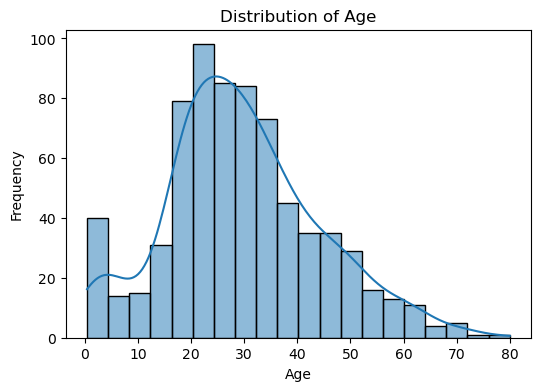

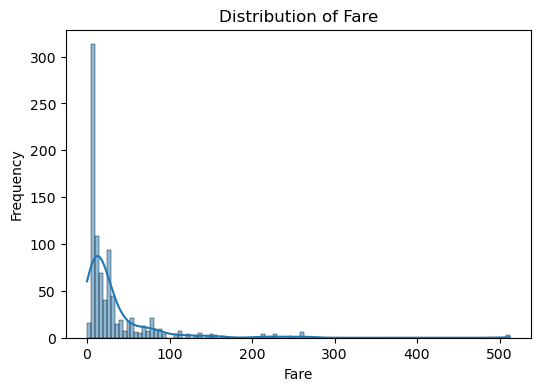

In [ ]:
for col in Numerical_Cols:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

## Categorical Columns

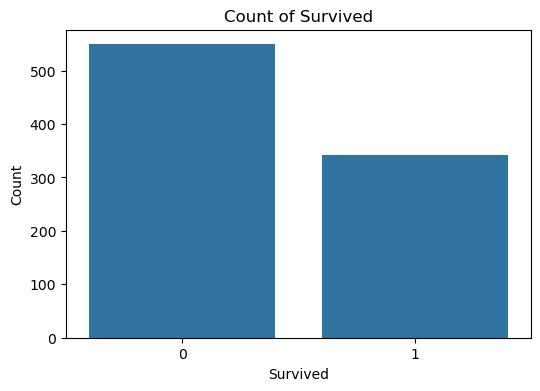

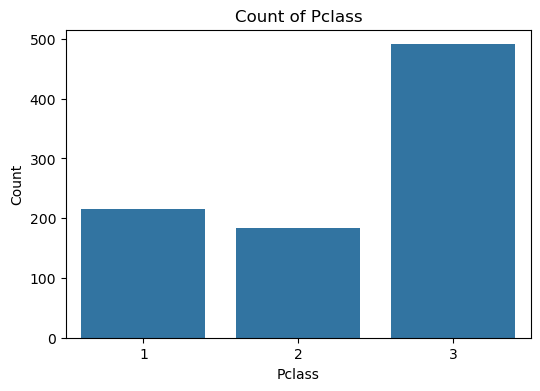

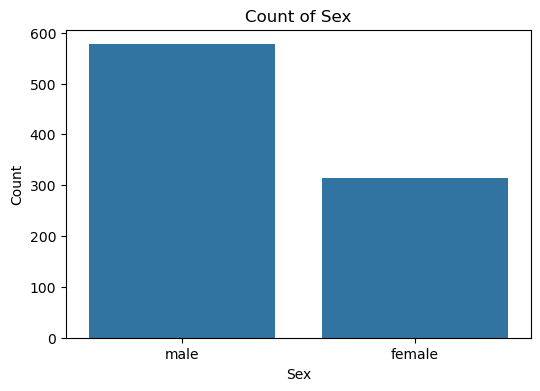

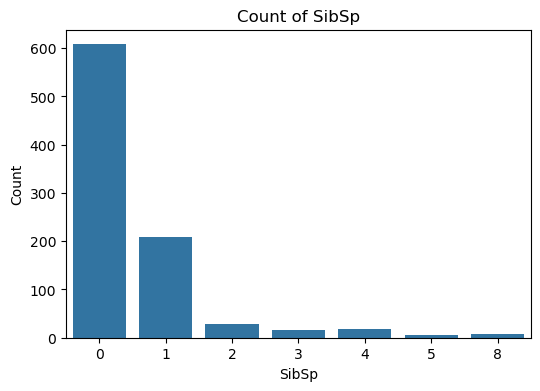

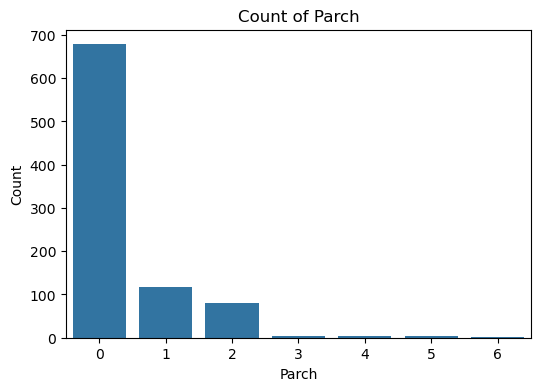

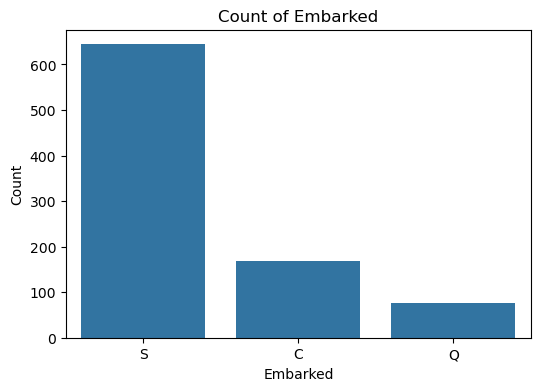

In [ ]:
for col in Categorical_Cols:
    plt.figure(figsize=(6,4))
    sns.countplot(x=df[col])
    plt.title(f'Count of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.show()

## Columns With Target

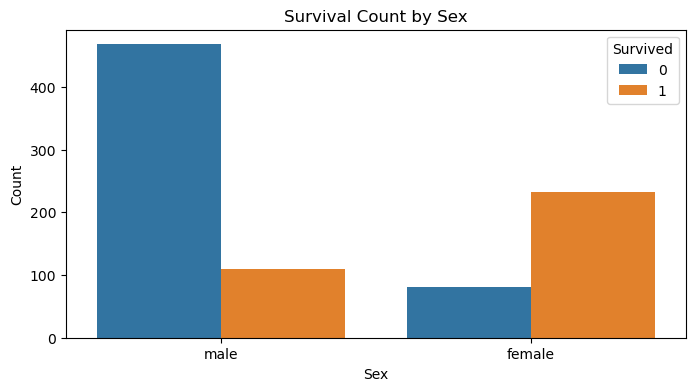

In [ ]:
plt.figure(figsize=(8,4))
sns.countplot(x='Sex', hue='Survived', data=df)
plt.title('Survival Count by Sex')
plt.xlabel('Sex')
plt.ylabel('Count')
plt.show()

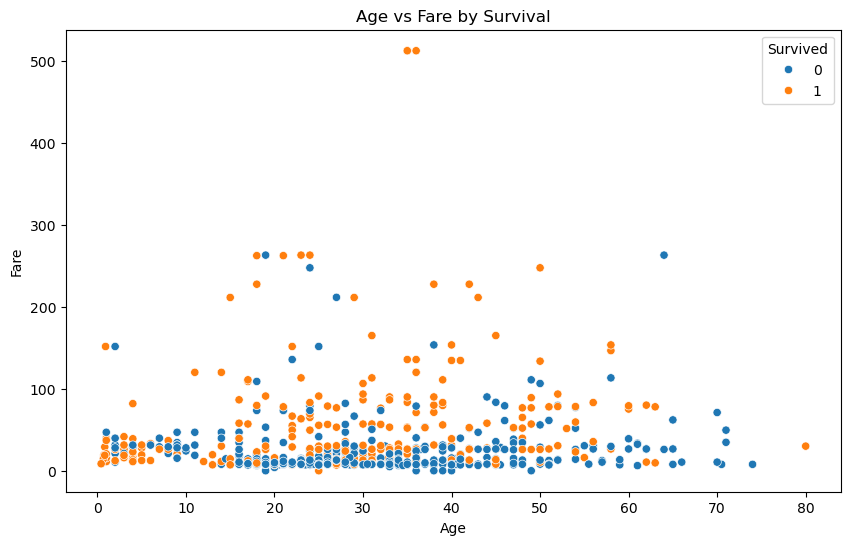

In [ ]:
plt.figure(figsize=(10,6))
sns.scatterplot(x='Age', y='Fare', hue='Survived', data=df)
plt.title('Age vs Fare by Survival')
plt.xlabel('Age')
plt.ylabel('Fare')
plt.show()

## Integrated Relations

<Axes: xlabel='Sex', ylabel='Age'>

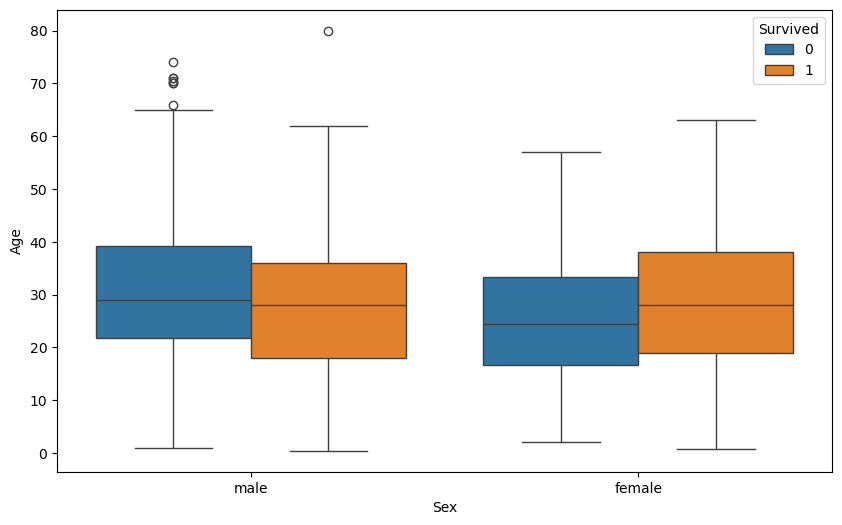

In [ ]:
plt.figure(figsize=(10,6))
sns.boxplot(x='Sex', y="Age", hue='Survived', data=df)

# Preprocessing

In [ ]:
data_info(df)

,Name,Data_Type,Top_10_Unique_Values,Nunique_Values,Nulls,Percent_of_Nulls,Duplicates
0,Survived,object,"[0, 1]",2,0,0.000000,111
1,Pclass,object,"[3, 1, 2]",3,0,0.000000,111
2,Sex,object,"[male, female]",2,0,0.000000,111
3,Age,float64,"[24.0, 22.0, 18.0, 19.0, 28.0, 30.0, 21.0, 25....",88,177,19.865320,111
4,SibSp,object,"[0, 1, 2, 4, 3, 8, 5]",7,0,0.000000,111
5,Parch,object,"[0, 1, 2, 5, 3, 4, 6]",7,0,0.000000,111
6,Fare,float64,"[8.05, 13.0, 7.8958, 7.75, 26.0, 10.5, 7.925, ...",248,0,0.000000,111
7,Embarked,object,"[S, C, Q]",3,2,0.224467,111


## Nulls

In [ ]:
df["Age"].fillna(df["Age"].median(), inplace=True)
df["Embarked"].fillna(df["Embarked"].mode()[0], inplace=True)

## Outliers

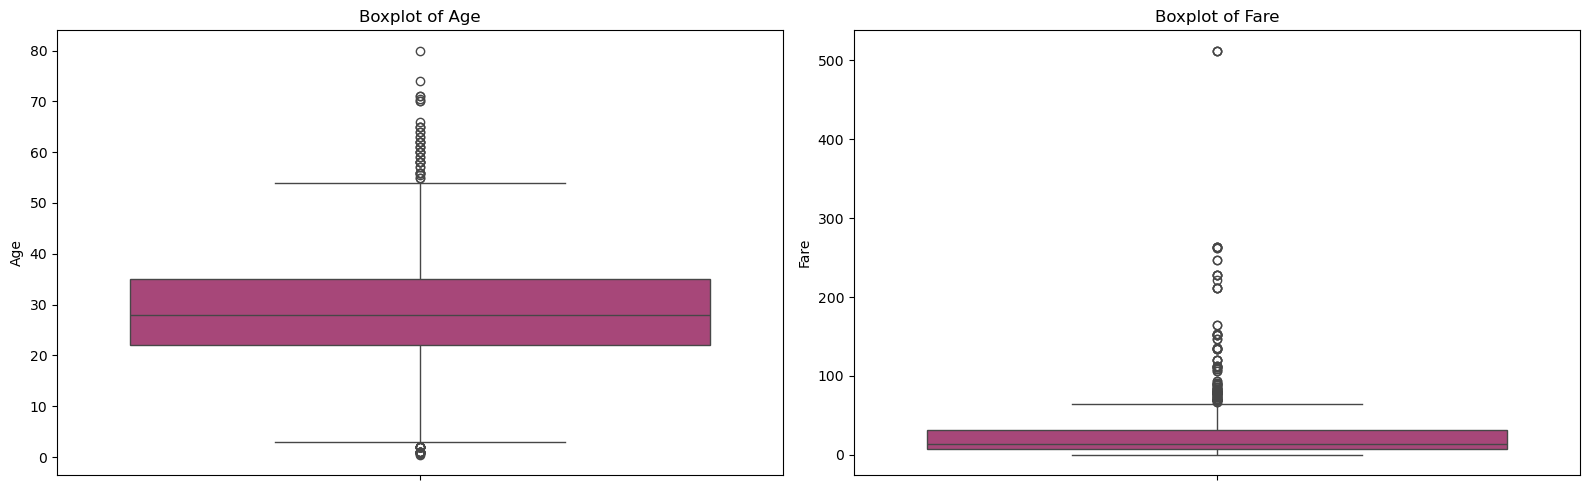

In [ ]:
checkOutliers=["Age","Fare"]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes = axes.flatten()

for i, col in enumerate(checkOutliers):
    sns.boxplot(data=df, y=col, ax=axes[i], palette='magma',whis=1.5)
    axes[i].set_title(f'Boxplot of {col}', fontsize=12)
    axes[i].set_xlabel('')
    axes[i].set_ylabel(col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


In [ ]:
# Function to handle outliers
def handle_Numerical_outliers(data):
    """
    This function handles outliers.
    """
    num_cols = data.select_dtypes(include="number").columns

    for col in num_cols:

        Q1=data[col].quantile(0.25)
        Q3=data[col].quantile(0.75)
        IQR=Q3-Q1

        lower_bound=Q1-(1.5*IQR)
        upper_bound=Q3+(1.5*IQR)

        data[col]=np.where(data[col]<lower_bound,lower_bound,data[col])
        data[col]=np.where(data[col]>upper_bound,upper_bound,data[col])

In [ ]:
handle_Numerical_outliers(df)

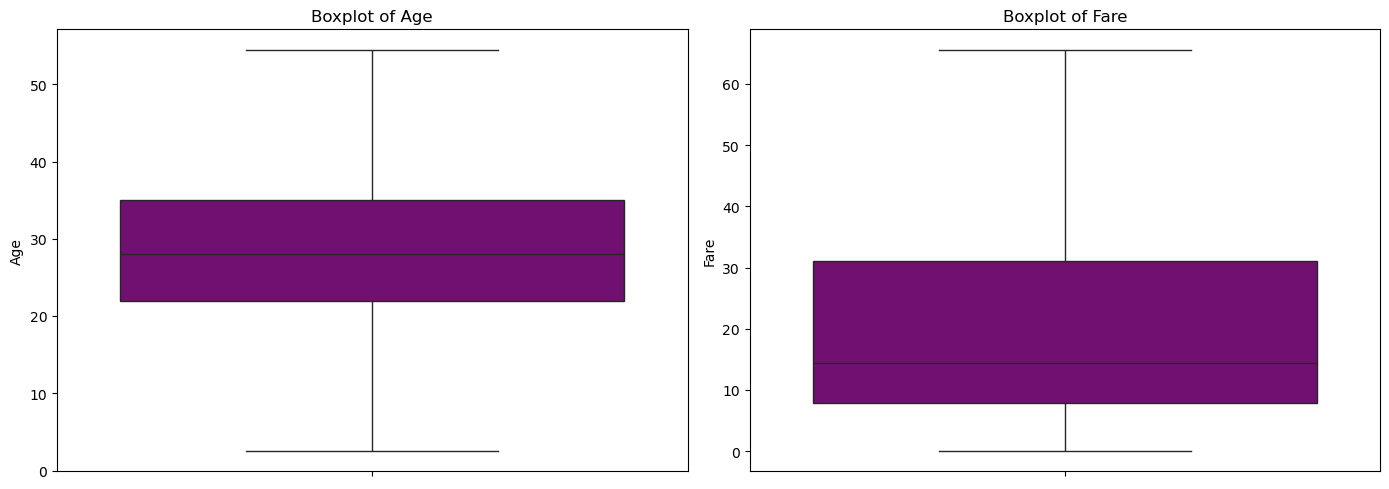

In [ ]:
n_cols = len(checkOutliers)

fig, axes = plt.subplots(1, n_cols, figsize=(7 * n_cols, 5))
axes = axes.flatten()

for i, col in enumerate(checkOutliers):
    sns.boxplot(
        data=df,
        y=col,
        ax=axes[i],
        color='purple',
        whis=1.5
    )
    axes[i].set_title(f'Boxplot of {col}', fontsize=12)
    axes[i].set_xlabel('')
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()


## Duplicates

In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
data_info(df)

,Name,Data_Type,Top_10_Unique_Values,Nunique_Values,Nulls,Percent_of_Nulls,Duplicates
0,Survived,object,"[0, 1]",2,0,0.0,0
1,Pclass,object,"[3, 1, 2]",3,0,0.0,0
2,Sex,object,"[male, female]",2,0,0.0,0
3,Age,float64,"[28.0, 54.5, 24.0, 18.0, 22.0, 19.0, 2.5, 21.0...",65,0,0.0,0
4,SibSp,object,"[0, 1, 2, 4, 3, 5, 8]",7,0,0.0,0
5,Parch,object,"[0, 1, 2, 5, 3, 4, 6]",7,0,0.0,0
6,Fare,float64,"[65.6344, 13.0, 26.0, 8.05, 10.5, 7.8958, 7.75...",204,0,0.0,0
7,Embarked,object,"[S, C, Q]",3,0,0.0,0


## Split Tha Data

In [ ]:
X=df.drop(columns=['Survived'])
y=df['Survived']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Encoding

In [ ]:
data_info(X_train)

,Name,Data_Type,Top_10_Unique_Values,Nunique_Values,Nulls,Percent_of_Nulls,Duplicates
0,Pclass,object,"[3, 1, 2]",3,0,0.0,10
1,Sex,object,"[male, female]",2,0,0.0,10
2,Age,float64,"[28.0, 54.5, 24.0, 22.0, 18.0, 21.0, 36.0, 30....",62,0,0.0,10
3,SibSp,object,"[0, 1, 2, 3, 4, 5, 8]",7,0,0.0,10
4,Parch,object,"[0, 1, 2, 3, 4, 5, 6]",7,0,0.0,10
5,Fare,float64,"[65.6344, 13.0, 26.0, 8.05, 7.8958, 7.75, 10.5...",183,0,0.0,10
6,Embarked,object,"[S, C, Q]",3,0,0.0,10


In [ ]:
Ordinal_Cols=["Pclass"]
Nominal_Cols=["Sex","Embarked","SibSp","Parch"]
Numerical_Cols=["Age", "Fare"]

In [ ]:
# Try One-Hot Encoding and Ordinal Encoding
for col in df.columns:

    if col in Ordinal_Cols:
        encoder = OrdinalEncoder(cols=[col])
        X_train[col] = encoder.fit_transform(X_train[col])
        X_test[col] = encoder.transform(X_test[col])

    elif col in Nominal_Cols:
        encoder = OneHotEncoder(cols=[col], use_cat_names=True)
        X_train = encoder.fit_transform(X_train)
        X_test = encoder.transform(X_test)

## Try Label Encoder

# for col in df.columns:
#     if col in Nominal_Cols:
#         encoder = LabelEncoder()
#         X_train[col] = encoder.fit_transform(X_train[col])
#         X_test[col] = encoder.transform(X_test[col])

In [ ]:
data_info(X_train)

,Name,Data_Type,Top_10_Unique_Values,Nunique_Values,Nulls,Percent_of_Nulls,Duplicates
0,Pclass,int32,"[1, 2, 3]",3,0,0.0,10
1,Sex_male,int64,"[1, 0]",2,0,0.0,10
2,Sex_female,int64,"[0, 1]",2,0,0.0,10
3,Age,float64,"[28.0, 54.5, 24.0, 22.0, 18.0, 21.0, 36.0, 30....",62,0,0.0,10
4,SibSp_1.0,int64,"[0, 1]",2,0,0.0,10
5,SibSp_0.0,int64,"[1, 0]",2,0,0.0,10
6,SibSp_5.0,int64,"[0, 1]",2,0,0.0,10
7,SibSp_3.0,int64,"[0, 1]",2,0,0.0,10
8,SibSp_2.0,int64,"[0, 1]",2,0,0.0,10
9,SibSp_4.0,int64,"[0, 1]",2,0,0.0,10


## Scaling

In [ ]:
# Scaler=RobustScaler()
# Scaler=MinMaxScaler()
Scaler=StandardScaler()

for col in Numerical_Cols:
    X_train[col] = Scaler.fit_transform(X_train[[col]])
    X_test[col] = Scaler.transform(X_test[[col]])

## Correlation

### Ordinal Columns (Spearman)

In [ ]:
# Ordinal VS Target (Nominal)

corr, p_value = spearmanr(X_train['Pclass'], y_train)
print(f"Spearman's correlation: {corr}, p-value: {p_value}")

Spearman's correlation: 0.28542519227065855, p-value: 7.017109744969149e-13


### Nominal Columns (Chi-Square)

In [ ]:
# for col in Nominal_Cols:
#     contingency = pd.crosstab(X_train[col], y_train)
#     chi2, p, dof, expected = chi2_contingency(contingency)

#     print("Chi2:", chi2)
#     print("p-value:", p)

encoded_cols = []
for col in Nominal_Cols:
    encoded_cols.extend([c for c in X_train.columns if c.startswith(col)])

chi_results = {}
for col in encoded_cols:
    contingency = pd.crosstab(X_train[col], y_train)
    chi2, p, dof, expected = chi2_contingency(contingency)
    chi_results[col] = {'Chi2': chi2, 'p-value': p}

chi_results_df = pd.DataFrame(chi_results).T.sort_values(by='Chi2', ascending=False)
print(chi_results_df)

                  Chi2       p-value
Sex_male    146.509863  1.004336e-33
Sex_female  146.509863  1.004336e-33
Embarked_C   11.599789  6.595929e-04
Parch_0.0     9.846198  1.701831e-03
Embarked_S    7.776826  5.292069e-03
Parch_1.0     6.721253  9.527065e-03
SibSp_1.0     4.759567  2.913587e-02
Parch_2.0     2.810322  9.365959e-02
SibSp_4.0     2.036721  1.535403e-01
SibSp_0.0     1.461641  2.266691e-01
Parch_4.0     0.731725  3.923245e-01
SibSp_5.0     0.731725  3.923245e-01
SibSp_3.0     0.695688  4.042363e-01
SibSp_2.0     0.510872  4.747617e-01
SibSp_8.0     0.209536  6.471313e-01
Parch_3.0     0.173235  6.772530e-01
Embarked_Q    0.080240  7.769721e-01
Parch_5.0     0.000000  1.000000e+00
Parch_6.0     0.000000  1.000000e+00


### Numerical (Point-Biserial)

In [ ]:
for col in Numerical_Cols:
    corr, p_value = pointbiserialr(y_train, X_train[col])
    print("column:", col, "Correlation:", corr, "p-value:", p_value)

column: Age Correlation: -0.05628791772229888 p-value: 0.16534565645786964
column: Fare Correlation: 0.2809005299725787 p-value: 1.6597073924608054e-12


### Columns to drop

In [ ]:
drop_cols = ['Age', "Parch_4.0", "SibSp_5.0", "SibSp_3.0", "SibSp_2.0"
            , "SibSp_8.0", "Parch_3.0", "Embarked_Q", "Parch_5.0", "Parch_6.0"]

# X_train.drop(columns=drop_cols, inplace=True)
# X_test.drop(columns=drop_cols, inplace=True)

## Balancing Data

In [ ]:
print(y_train.value_counts())

Survived
0    360
1    249
Name: count, dtype: int64


In [ ]:
y_train=y_train.astype('int')
y_test=y_test.astype('int')

In [ ]:
# Generates new synthetic samples
smote=SMOTE(random_state=42)
X_train, y_train = smote.fit_resample(X_train, y_train)

print(y_train.value_counts())

Survived
0    360
1    360
Name: count, dtype: int64


# Model Training

## Logistic Regression With Grid Search

In [ ]:
log_reg = LogisticRegression(max_iter=1000, random_state=42)

param_grid = {
    'penalty': ['l1', 'l2'],
    'C': [0.01, 0.1, 1, 10, 100],
    'class_weight': [None, 'balanced']
}

grid_search = GridSearchCV(
    estimator=log_reg,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)
best_log_reg = grid_search.best_estimator_

y_pred = best_log_reg.predict(X_test)
y_pred_train = best_log_reg.predict(X_train)

print("Best Parameters:", grid_search.best_params_)
print("Train Accuracy:", accuracy_score(y_train, y_pred_train))
print("Test Accuracy:", accuracy_score(y_test, y_pred))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters: {'C': 10, 'class_weight': None, 'penalty': 'l2'}
Train Accuracy: 0.7666666666666667
Test Accuracy: 0.8104575163398693


### Logistic Regression best Parameters

In [ ]:
log_reg_final=LogisticRegression(C=100, class_weight=None, penalty='l2', max_iter=1000, random_state=42)
log_reg_final.fit(X_train, y_train)

y_pred_final = log_reg_final.predict(X_test)
y_pred_train_final = log_reg_final.predict(X_train)

print("Train Accuracy:", accuracy_score(y_train, y_pred_train_final))
print("Test Accuracy:", accuracy_score(y_test, y_pred_final))

print(classification_report(y_test, y_pred_final, target_names=['Not Survived', 'Survived']))

Train Accuracy: 0.7680555555555556
Accuracy: 0.8169934640522876
              precision    recall  f1-score   support

Not Survived       0.79      0.93      0.86        89
    Survived       0.88      0.66      0.75        64

    accuracy                           0.82       153
   macro avg       0.83      0.79      0.80       153
weighted avg       0.83      0.82      0.81       153



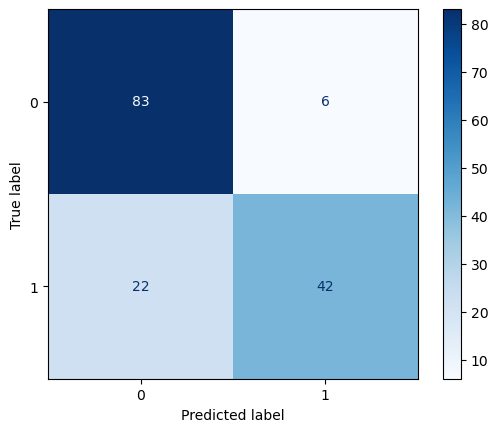

In [ ]:
ConfusionMatrixDisplay.from_estimator(
    log_reg_final,
    X_test,
    y_test,
    cmap=plt.cm.Blues
)
plt.show()

## SVM With Grid Search

In [ ]:
svm_model = SVC(probability=True, random_state=42)

param_grid = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf', 'poly'],
    'gamma': ['scale', 'auto'],
    'class_weight': [None, 'balanced']
}

grid_search = GridSearchCV(
    estimator=svm_model,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
)

grid_search.fit(X_train, y_train)
best_svm = grid_search.best_estimator_

y_pred = best_svm.predict(X_test)
y_pred_train = best_svm.predict(X_train)

print("Best Parameters:", grid_search.best_params_)
print("Train Accuracy:", accuracy_score(y_train, y_pred_train))
print("Test Accuracy:", accuracy_score(y_test, y_pred))

Best Parameters: {'C': 10, 'class_weight': None, 'gamma': 'auto', 'kernel': 'rbf'}
Train Accuracy: 0.8194444444444444
Test Accuracy: 0.803921568627451


### SVM Best Parameters

In [ ]:
svm_final = SVC(C=10, kernel='rbf', gamma='auto', class_weight=None, probability=True, random_state=42)
svm_final.fit(X_train, y_train)

y_pred_final = svm_final.predict(X_test)
y_pred_train_final = svm_final.predict(X_train)

print("Train Accuracy:", accuracy_score(y_train, y_pred_train_final))
print("Accuracy:", accuracy_score(y_test, y_pred_final))

print(classification_report(y_test, y_pred_final, target_names=['Not Survived', 'Survived']))

Train Accuracy: 0.8194444444444444
Accuracy: 0.803921568627451
              precision    recall  f1-score   support

Not Survived       0.78      0.92      0.85        89
    Survived       0.85      0.64      0.73        64

    accuracy                           0.80       153
   macro avg       0.82      0.78      0.79       153
weighted avg       0.81      0.80      0.80       153



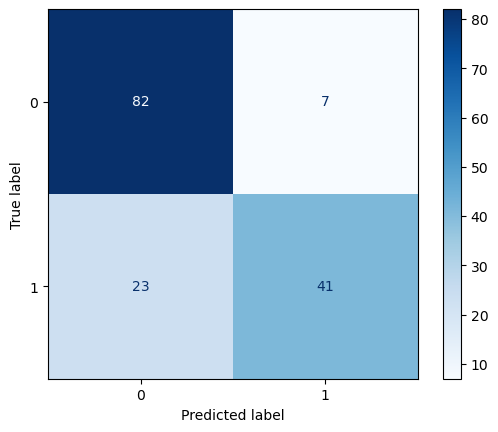

In [ ]:
ConfusionMatrixDisplay.from_estimator(
    svm_final,
    X_test,
    y_test,
    cmap=plt.cm.Blues
)
plt.show()

## Decision Tree With Grid Search

In [ ]:
dt= DecisionTreeClassifier(random_state=42)

param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'class_weight': [None, 'balanced']
}
grid_search = GridSearchCV(
    estimator=dt,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)
grid_search.fit(X_train, y_train)
best_dt = grid_search.best_estimator_

y_pred = best_dt.predict(X_test)
y_pred_train = best_dt.predict(X_train)

print("Best Parameters:", grid_search.best_params_)
print("Train Accuracy:", accuracy_score(y_train, y_pred_train))
print("Test Accuracy:", accuracy_score(y_test, y_pred))

Fitting 5 folds for each of 144 candidates, totalling 720 fits


Best Parameters: {'class_weight': None, 'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 10}
Train Accuracy: 0.8763888888888889
Test Accuracy: 0.7647058823529411


### Decision Tree Best Parameters

In [ ]:
dt= DecisionTreeClassifier(criterion='gini', max_depth=10, min_samples_leaf=1,
                            min_samples_split=10, class_weight=None, random_state=42)

dt.fit(X_train, y_train)

y_pred_final = dt.predict(X_test)
y_pred_train_final = dt.predict(X_train)

print("Train Accuracy:", accuracy_score(y_train, y_pred_train_final))
print("Test Accuracy:", accuracy_score(y_test, y_pred_final))

print(classification_report(y_test, y_pred_final, target_names=['Not Survived', 'Survived']))

Train Accuracy: 0.8763888888888889
Test Accuracy: 0.7647058823529411
              precision    recall  f1-score   support

Not Survived       0.77      0.84      0.81        89
    Survived       0.75      0.66      0.70        64

    accuracy                           0.76       153
   macro avg       0.76      0.75      0.75       153
weighted avg       0.76      0.76      0.76       153



## RandomForest with Grid Search

In [ ]:
rf= RandomForestClassifier(random_state=42)

param_grid = {
    'n_estimators': [100, 200, 300],
    'criterion': ['gini', 'entropy'],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'class_weight': [None, 'balanced']
}

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)
best_rf = grid_search.best_estimator_

y_pred = best_rf.predict(X_test)
y_pred_train = best_rf.predict(X_train)

print("Best Parameters:", grid_search.best_params_)
print("Train Accuracy:", accuracy_score(y_train, y_pred_train))
print("Test Accuracy:", accuracy_score(y_test, y_pred))

Fitting 5 folds for each of 144 candidates, totalling 720 fits
Best Parameters: {'class_weight': None, 'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
Train Accuracy: 0.8708333333333333
Test Accuracy: 0.7777777777777778


In [ ]:
rf_final = RandomForestClassifier(criterion='gini', max_depth=20, min_samples_leaf=1,
                                  min_samples_split=2, n_estimators=300, class_weight=None, random_state=42)
rf_final.fit(X_train, y_train)

y_pred_final = rf_final.predict(X_test)
y_pred_train_final = rf_final.predict(X_train)

print("Train Accuracy:", accuracy_score(y_train, y_pred_train_final))
print("Test Accuracy:", accuracy_score(y_test, y_pred_final))

print(classification_report(y_test, y_pred_final, target_names=['Not Survived', 'Survived']))

Train Accuracy: 0.9861111111111112
Test Accuracy: 0.7450980392156863
              precision    recall  f1-score   support

Not Survived       0.76      0.83      0.79        89
    Survived       0.73      0.62      0.67        64

    accuracy                           0.75       153
   macro avg       0.74      0.73      0.73       153
weighted avg       0.74      0.75      0.74       153



## XGBoost with Grid Search

In [ ]:
xgb= XGBClassifier(random_state=42)

param_grid = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 4, 5],
    'min_child_weight': [1, 2, 3],
    'gamma': [0, 0.1, 0.2],
    'class_weight': [None, 'balanced']
}

grid_search = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)
best_xgb = grid_search.best_estimator_

y_pred = best_xgb.predict(X_test)
y_pred_train = best_xgb.predict(X_train)

print("Best Parameters:", grid_search.best_params_)
print("Train Accuracy:", accuracy_score(y_train, y_pred_train))
print("Test Accuracy:", accuracy_score(y_test, y_pred))

Fitting 5 folds for each of 486 candidates, totalling 2430 fits
Best Parameters: {'class_weight': None, 'gamma': 0.1, 'learning_rate': 0.1, 'max_depth': 3, 'min_child_weight': 2, 'n_estimators': 100}
Train Accuracy: 0.8694444444444445
Test Accuracy: 0.7908496732026143


### XGB Best Parameters

In [ ]:
xgb_final = XGBClassifier(learning_rate=0.1, max_depth=3, n_estimators=100,
                          colsample_bytree=0.8, gamma=0.1, class_weight=None, random_state=42)
xgb_final.fit(X_train, y_train)

y_pred_final = xgb_final.predict(X_test)
y_pred_train_final = xgb_final.predict(X_train)

print("Train Accuracy:", accuracy_score(y_train, y_pred_train_final))
print("Test Accuracy:", accuracy_score(y_test, y_pred_final))

print(classification_report(y_test, y_pred_final, target_names=['Not Survived', 'Survived']))

Train Accuracy: 0.8666666666666667
Test Accuracy: 0.7908496732026143
              precision    recall  f1-score   support

Not Survived       0.78      0.89      0.83        89
    Survived       0.81      0.66      0.72        64

    accuracy                           0.79       153
   macro avg       0.79      0.77      0.78       153
weighted avg       0.79      0.79      0.79       153



## Roc Curve

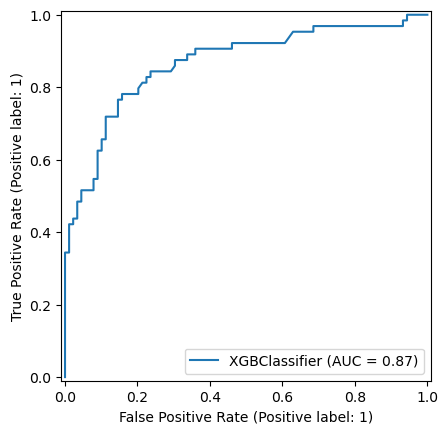

In [ ]:
RocCurveDisplay.from_estimator(xgb_final, X_test, y_test);